In [1]:
# === Ô GHI LOG  ===
import logging, sys, datetime, warnings
from pathlib import Path
TEN_NOTEBOOK = "01_E0.3_ngoai_lai_da_cong_tuyen_Han"
NGUOI_CHAY   = "Han"

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data").exists())  # thư mục gốc repo
thu_muc_log = ROOT / "logs" / "eda_log"   # log các notebook EDA để riêng
thu_muc_log.mkdir(parents=True, exist_ok=True)
file_log = thu_muc_log / f"{datetime.datetime.now():%Y-%m-%d_%H%M}_{TEN_NOTEBOOK}.log"
tep_log = open(file_log, "a", encoding="utf-8", buffering=1)

if hasattr(sys.stdout, "echo"):                  # chạy trong Jupyter / VS Code: nhờ kernel chép thêm ra file, không thay sys.stdout
    sys.stdout.echo = tep_log
    sys.stderr.echo = tep_log
else:                                            # chạy bằng python thường
    class GhiCaHai:
        def __init__(self, man_hinh, tep): self.man_hinh, self.tep = man_hinh, tep
        def write(self, s): self.man_hinh.write(s); self.tep.write(s); return len(s)
        def flush(self): self.man_hinh.flush(); self.tep.flush()
        def __getattr__(self, ten): return getattr(self.man_hinh, ten)
    sys.stdout = GhiCaHai(sys.__stdout__, tep_log)

logging.basicConfig(stream=sys.stdout, level=logging.INFO, force=True,
                    format="%(asctime)s | %(levelname)s | %(message)s", datefmt="%Y-%m-%d %H:%M:%S")
logging.captureWarnings(True)
log = logging.getLogger(TEN_NOTEBOOK)
log.info(f"Bắt đầu chạy {TEN_NOTEBOOK} – người chạy: {NGUOI_CHAY} – file log: {file_log}")

2026-11-14 18:10:11 | INFO | Bắt đầu chạy 01_E0.3_ngoai_lai_da_cong_tuyen_Han – người chạy: Han – file log: /Users/caongochan/Documents/Challenge_2_Music_Genre_Classification/logs/2026-11-14_1810_01_E0.3_ngoai_lai_da_cong_tuyen_Han.log


# E0.3 – Có ngoại lai, đa cộng tuyến không? (C2 – Music Genre)

| | |
|---|---|
| **Tác giả** | Cao Ngọc Hân – Nhóm 11 |
| **Ngày tạo** | 14/11/2026 |
| **Thí nghiệm** | E0.3 – Có ngoại lai, đa cộng tuyến không? |
| **Câu hỏi nghiên cứu** | RQ0: Đặc trưng âm thanh nào phân biệt các thể loại tốt nhất? |
| **Đọc vào** | `data/raw/train.csv` |
| **Ghi ra** | `figures/eda/c2_E0.3_*` (ngoại lai IQR, cặp tương quan cao, VIF, 1 hình), `c2_E0.3_tom_tat.txt` |

**Lịch sử sửa**

| Ngày | Người | Nội dung |
|---|---|---|
| 08/11/2026 | Hân | Viết trong `01_eda_Han.ipynb` (E0.1–E0.6 chung một notebook) |
| 14/11/2026 | Hân | Tách thành notebook riêng; thêm ô ghi log ra `logs/` |

Notebook chỉ dùng thống kê và mô hình đơn giản (hồi quy logistic). Mô hình mạnh là việc của Nhung.

**Cách chạy:** chạy các notebook EDA theo thứ tự E0.1 → E0.6 (Run All). File log nằm ở `logs/eda_log/`. Bản gộp đọc từ trên xuống: `00_EDA_tong_hop_C2_Han.ipynb`.

In [2]:
import os, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.feature_selection import mutual_info_classif, f_classif
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 100)
sns.set_theme(style="whitegrid", font_scale=1.0)

SEED = 42
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data").exists())  # notebook nằm ở notebooks/eda/
DATA = ROOT / "data" / "raw"
FIG = ROOT / "figures" / "eda"
FIG.mkdir(parents=True, exist_ok=True)

# W&B: USE_WANDB là công tắc chung; LOG chọn thí nghiệm nào được log ở lần chạy này.
# Các run W&B của E0.1–E0.6 đã log ngày 08/11 (từ 01_eda_Han.ipynb).
# Để USE_WANDB = False khi chạy lại để không tạo run trùng; bật True nếu cần log run mới.
USE_WANDB = False
LOG = {"E0.3": True}
WANDB_ENTITY = "sgu-mayhoc-nhom11"
WANDB_PROJECT = "challenge-2-music-genre-classification"
log.info(f"ROOT: {ROOT}")

2026-11-14 18:10:13 | INFO | ROOT: /Users/caongochan/Documents/Challenge_2_Music_Genre_Classification


In [3]:
train = pd.read_csv(DATA / "train.csv")
test = pd.read_csv(DATA / "test.csv")
TARGET, ID = "Class", "Id"
TEXT_COLS = ["Artist Name", "Track Name"]
print("train:", train.shape, "| test:", test.shape)
train.head()

train: (14396, 18) | test: (3600, 17)


,Id,Artist Name,Track Name,Popularity,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_in min/ms,time_signature,Class
0,1,Marina Maximilian,Not Afraid,37.0,0.334,0.536,9.0,-6.649,0,0.0381,0.378000,NaN,0.106,0.235,152.429,204947.0,4,9
1,2,The Black Keys,Howlin' for You,67.0,0.725,0.747,11.0,-5.545,1,0.0876,0.027200,0.0468,0.104,0.380,132.921,191956.0,4,6
2,3,Royal & the Serpent,phuck u,NaN,0.584,0.804,7.0,-6.094,1,0.0619,0.000968,0.6350,0.284,0.635,159.953,161037.0,4,10
3,4,Detroit Blues Band,Missing You,12.0,0.515,0.308,NaN,-14.711,1,0.0312,0.907000,0.0213,0.300,0.501,172.472,298093.0,3,2
4,5,Coast Contra,My Lady,48.0,0.565,0.777,6.0,-5.096,0,0.2490,0.183000,NaN,0.211,0.619,88.311,254145.0,4,5


In [4]:
# Chuẩn bị chung (lấy lại từ E0.1, E0.2): tách đặc trưng; đổi thời lượng về phút và điền thiếu bằng trung vị
# (chỉ để phân tích, không phải pipeline mô hình); 5 fold phân tầng và hồi quy logistic dùng chung
X = train.drop(columns=[ID, TARGET])
y = train[TARGET]
num_cols = [c for c in X.columns if c not in TEXT_COLS]
Xa = X[num_cols].copy()
Xa["duration_in min/ms"] = np.where(Xa["duration_in min/ms"] < 30, Xa["duration_in min/ms"],
                                    Xa["duration_in min/ms"] / 60000)
Xa = Xa.rename(columns={"duration_in min/ms": "duration_min"})
num_cols = list(Xa.columns)
Xa = Xa.fillna(Xa.median())

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
def logit():
    return make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, class_weight="balanced"))
baseline_f1 = 1 / y.nunique()
log.info(f"{len(num_cols)} đặc trưng số, {y.nunique()} thể loại, macro-F1 ngẫu nhiên ≈ {baseline_f1:.3f}")

2026-11-14 18:10:13 | INFO | 14 đặc trưng số, 11 thể loại, macro-F1 ngẫu nhiên ≈ 0.091


## E0.3 – Có ngoại lai, đa cộng tuyến không?

- **Ngoại lai:** số điểm nằm ngoài [Q1 − 3·IQR, Q3 + 3·IQR] ở từng đặc trưng (sau khi đã đổi thời lượng về phút).
- **Đa cộng tuyến:** ma trận tương quan, các cặp |r| > 0.7, và hệ số VIF (VIF > 10 là đa cộng tuyến mạnh).

In [5]:
q1, q3 = Xa.quantile(0.25), Xa.quantile(0.75)
iqr = q3 - q1
extreme = ((Xa < q1 - 3 * iqr) | (Xa > q3 + 3 * iqr)) & (iqr > 0)
iqr_tbl = extreme.sum().sort_values(ascending=False).to_frame("so_diem_ngoai_lai")
iqr_tbl["ti_le"] = iqr_tbl["so_diem_ngoai_lai"] / len(Xa)
iqr_tbl = iqr_tbl.query("so_diem_ngoai_lai > 0")
iqr_tbl.to_csv(FIG / "c2_E0.3_ngoai_lai_IQR.csv")
print("Đặc trưng có ngoại lai cực đoan:")
iqr_tbl.style.format({"ti_le": "{:.1%}"})

Đặc trưng có ngoại lai cực đoan:


,so_diem_ngoai_lai,ti_le
instrumentalness,2607,18.1%
speechiness,1016,7.1%
liveness,259,1.8%
duration_min,206,1.4%
loudness,146,1.0%


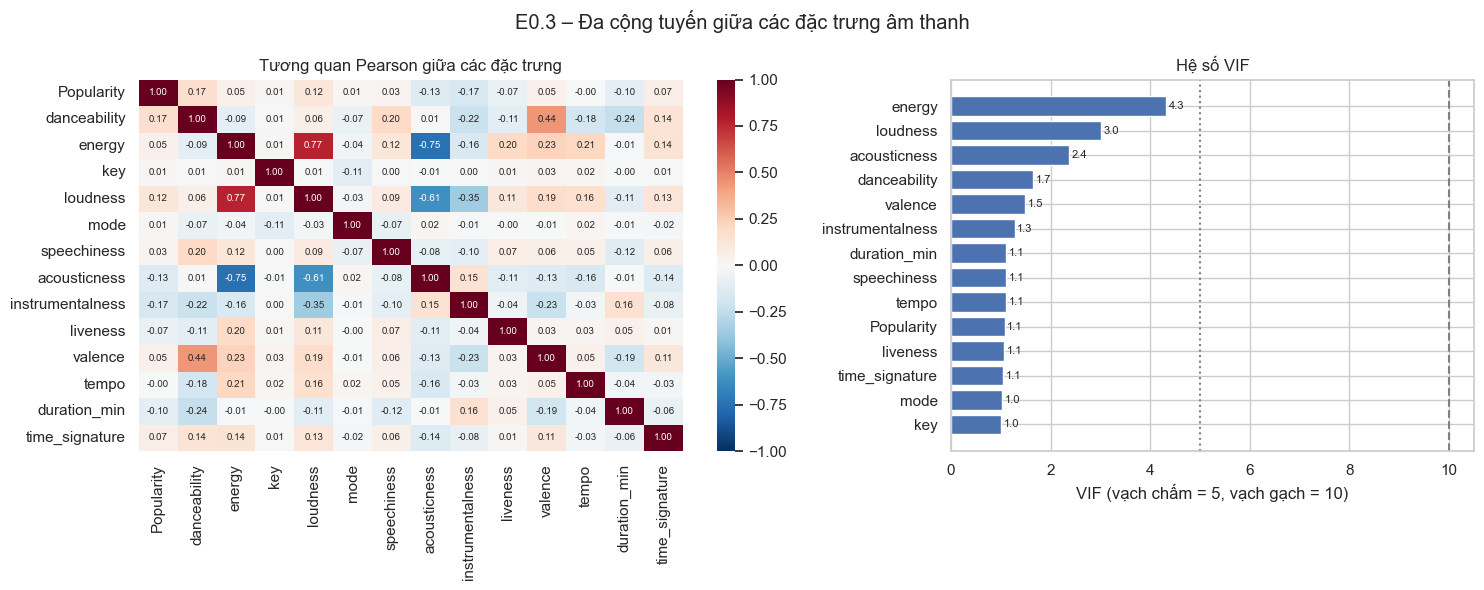

Cặp |tương quan| > 0.7:
dac_trung_1  dac_trung_2  tuong_quan
     energy     loudness        0.77
     energy acousticness       -0.75
VIF lớn nhất: energy 4.32


In [6]:
corr = Xa.corr()
pairs = (corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
             .rename("tuong_quan").reset_index().rename(columns={"level_0": "dac_trung_1", "level_1": "dac_trung_2"}))
high_corr = pairs[pairs["tuong_quan"].abs() > 0.7].sort_values("tuong_quan", key=abs, ascending=False)
high_corr.to_csv(FIG / "c2_E0.3_cap_tuong_quan_cao.csv", index=False)

def vif_table(df):
    out = {}
    for c in df.columns:
        others = df.drop(columns=c)
        r2 = LinearRegression().fit(others, df[c]).score(others, df[c])
        out[c] = np.inf if r2 > 0.9999 else 1 / (1 - r2)
    return pd.Series(out).sort_values(ascending=False)
vif = vif_table(Xa).to_frame("VIF")
vif.to_csv(FIG / "c2_E0.3_vif.csv")

fig, axes = plt.subplots(1, 2, figsize=(15, 6), gridspec_kw={"width_ratios": [1.3, 1]})
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, ax=axes[0], annot_kws={"size": 7})
axes[0].set_title("Tương quan Pearson giữa các đặc trưng")
colors = ["#C44E52" if v > 10 else ("#DD8452" if v > 5 else "#4C72B0") for v in vif["VIF"]]
axes[1].barh(vif.index[::-1], vif["VIF"][::-1], color=colors[::-1])
for i, v in enumerate(vif["VIF"][::-1]):
    axes[1].text(v + 0.05, i, f"{v:.1f}", va="center", fontsize=8)
axes[1].axvline(5, ls=":", color="gray"); axes[1].axvline(10, ls="--", color="gray")
axes[1].set_xlabel("VIF (vạch chấm = 5, vạch gạch = 10)"); axes[1].set_title("Hệ số VIF")
fig.suptitle("E0.3 – Đa cộng tuyến giữa các đặc trưng âm thanh")
plt.tight_layout(); plt.savefig(FIG / "c2_E0.3_tuong_quan_vif.png", dpi=150); plt.show()
print("Cặp |tương quan| > 0.7:"); print(high_corr.round(2).to_string(index=False))
print("VIF lớn nhất:", vif["VIF"].idxmax(), round(float(vif["VIF"].max()), 2))

## Tóm tắt E0.3

In [7]:
summary = f"""E0.3 (C2): ngoại lai cực đoan nhiều nhất ở {', '.join(f'{c} ({p:.1%})' for c, p in iqr_tbl['ti_le'].head(3).items())}.
  Cặp tương quan > 0.7: {'; '.join(f'{a}–{b} ({r:.2f})' for a, b, r in high_corr.itertuples(index=False)) or 'không có'}. VIF lớn nhất {vif['VIF'].idxmax()} = {vif['VIF'].max():.1f}."""
log.info("Tóm tắt E0.3:\n" + summary)
(FIG / "c2_E0.3_tom_tat.txt").write_text(summary, encoding="utf-8")

2026-11-14 18:10:13 | INFO | Tóm tắt E0.3:
E0.3 (C2): ngoại lai cực đoan nhiều nhất ở instrumentalness (18.1%), speechiness (7.1%), liveness (1.8%).
  Cặp tương quan > 0.7: energy–loudness (0.77); energy–acousticness (-0.75). VIF lớn nhất energy = 4.3.


209

## Log lên W&B (minh chứng)

In [8]:
if USE_WANDB:
    import wandb
    def log_run(exp, name, metrics, tables, images, config=None):
        if not LOG.get(exp):
            print(f"Bỏ qua {exp} (LOG = False)"); return
        run = wandb.init(entity=WANDB_ENTITY, project=WANDB_PROJECT, name=name,
                         tags=[exp, "Han", "EDA"], config={"seed": SEED, **(config or {})})
        run.log({**metrics,
                 **{k: wandb.Table(dataframe=v) for k, v in tables.items()},
                 **{f.removesuffix(".png"): wandb.Image(str(FIG / f)) for f in images}})
        run.finish()

    log_run("E0.3", "c2-E0.3-Han-ngoai-lai-da-cong-tuyen",
            {"n_features_extreme_outliers": len(iqr_tbl), "n_high_corr_pairs": len(high_corr),
             "max_vif": float(vif["VIF"].max())},
            {"ngoai_lai": iqr_tbl.reset_index(names="dac_trung"), "cap_tuong_quan_cao": high_corr.round(3),
             "vif": vif.round(2).reset_index(names="dac_trung")},
            ["c2_E0.3_tuong_quan_vif.png"], {"iqr_k": 3, "corr_threshold": 0.7})

## Nhật ký

- 08/11/2026 – Viết E0.3 lần đầu trong notebook `01_eda_Han.ipynb`. Commit `3f161ad`.
- 14/11/2026 – Tách E0.3 ra thành notebook riêng `01_E0.3_ngoai_lai_da_cong_tuyen_Han.ipynb`, thêm ô ghi log. Commit `eaa2795`.